# Module 05, Part 2: Multi-head attention

This notebook is the runnable companion to Part 2 of the Module 05 learning
content. It checks, with code:

1. Multi-head attention is one reshape around the scaled dot-product attention of
   Part 1, and the number of parameters does not depend on the number of heads.
2. Our implementation matches `nn.MultiheadAttention` once the weights are copied
   across.
3. What trained heads actually do. We train a small model on a task that needs
   two lookups, look at every head's attention pattern, and switch heads off one
   at a time.

The third part is an experiment, not a demonstration. What the heads learn is
less tidy than the usual pictures suggest, and the notebook reports it as it is.
Everything runs on CPU in a few minutes.

In [1]:
import math
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)

def causal_mask(length):
    """Boolean mask of shape (length, length). True means 'this position may be attended to'.
    Row i (the query) may look at columns 0..i (the keys), never at the future."""
    return torch.tril(torch.ones(length, length, dtype=torch.bool))


def scaled_dot_product_attention(q, k, v, mask=None, scale=True):
    """softmax(q k^T / sqrt(d_k)) v.

    q: (..., T_q, d_k)   k: (..., T_k, d_k)   v: (..., T_k, d_v)
    mask: boolean, broadcastable to (..., T_q, T_k); False entries are blocked.
    Returns (output, weights). Set scale=False to see why the scaling matters.
    """
    d_k = q.shape[-1]
    scores = q @ k.transpose(-2, -1)
    if scale:
        scores = scores / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ v, weights

PyTorch version: 2.10.0+cpu


## 1. Multi-head attention is a reshape

A single attention head produces **one** pattern of weights per query: one blend
of the values. Multi-head attention runs several heads side by side, each on its
own lower-dimensional slice, so a position can blend different things in different
ways at the same time.

Mechanically: project the input to queries, keys and values of width `d_model`;
reshape each into `n_heads` slices of width `d_head = d_model / n_heads`; run
scaled dot-product attention on every slice at once; concatenate the slices back
to `d_model`; mix with one more linear layer.

In [2]:
class MultiHeadAttention(nn.Module):
    """Several attention heads that run side by side on lower-dimensional projections.

    d_model is split into n_heads slices of size d_model // n_heads. Each head has
    its own query, key and value projection (stored together in one weight matrix
    each), attends on its own, and the head outputs are concatenated and mixed by
    a final linear layer.
    """

    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model, self.n_heads, self.d_head = d_model, n_heads, d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)

    def split_heads(self, x):
        batch, length, _ = x.shape
        return x.view(batch, length, self.n_heads, self.d_head).transpose(1, 2)  # (batch, heads, T, d_head)

    def forward(self, x, context=None, mask=None, head_mask=None, return_weights=False):
        """x supplies the queries. context supplies keys and values (cross-attention);
        by default it is x itself (self-attention). head_mask is an optional tensor of
        shape (n_heads,) of 0/1 values used to switch individual heads off."""
        context = x if context is None else context
        q = self.split_heads(self.w_q(x))
        k = self.split_heads(self.w_k(context))
        v = self.split_heads(self.w_v(context))
        out, weights = scaled_dot_product_attention(q, k, v, mask=mask)
        if head_mask is not None:
            out = out * head_mask.view(1, -1, 1, 1)
        batch, _, length, _ = out.shape
        out = out.transpose(1, 2).reshape(batch, length, self.d_model)  # concatenate the heads
        out = self.w_o(out)
        return (out, weights) if return_weights else out

In [3]:
d_model, n_heads = 32, 4
mha = MultiHeadAttention(d_model, n_heads)
x = torch.randn(3, 6, d_model)
out, weights = mha(x, return_weights=True)
print("input:", tuple(x.shape), " output:", tuple(out.shape), " weights:", tuple(weights.shape), "(batch, heads, queries, keys)")

count = lambda m: sum(p.numel() for p in m.parameters())
print("parameters with 1, 2, 4, 8 heads:", [count(MultiHeadAttention(d_model, h)) for h in (1, 2, 4, 8)])

input: (3, 6, 32)  output: (3, 6, 32)  weights: (3, 4, 6, 6) (batch, heads, queries, keys)
parameters with 1, 2, 4, 8 heads: [4224, 4224, 4224, 4224]


The parameter count is identical for 1, 2, 4 or 8 heads. Splitting does not add
parameters; it divides the same width into independent attention patterns. The
price of more heads is a narrower slice per head.

### Same as PyTorch's layer

`nn.MultiheadAttention` stores the query, key and value projections stacked in a
single `in_proj_weight`, in that order. We copy them across and compare.

In [4]:
reference = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
with torch.no_grad():
    W, b = reference.in_proj_weight, reference.in_proj_bias            # (3 * d_model, d_model): query, key, value
    mha.w_q.weight.copy_(W[:d_model]);               mha.w_q.bias.copy_(b[:d_model])
    mha.w_k.weight.copy_(W[d_model:2 * d_model]);    mha.w_k.bias.copy_(b[d_model:2 * d_model])
    mha.w_v.weight.copy_(W[2 * d_model:]);           mha.w_v.bias.copy_(b[2 * d_model:])
    mha.w_o.weight.copy_(reference.out_proj.weight); mha.w_o.bias.copy_(reference.out_proj.bias)

print("Our multi-head attention matches nn.MultiheadAttention:",
      torch.allclose(mha(x), reference(x, x, x)[0], atol=1e-5))

Our multi-head attention matches nn.MultiheadAttention: True


## 2. What do the heads learn? An experiment

The task needs **two lookups**. For every position $i$ of a sequence of 12 tokens
(a ring, so position 0 sits next to position 11), the target is the sum of the
two neighbours' tokens, modulo 6:

$$y_i = (x_{i-1} + x_{i+1}) \bmod 6$$

The model has one attention layer with 4 heads, learned position embeddings and a
linear read-out at every position. We train it three times with different seeds.

In [5]:
def make_neighbour_batch(batch_size, seq_len, generator, vocab=6):
    """Neighbour task. Predict, at every position i, (token[i-1] + token[i+1]) mod vocab, with the
    sequence treated as a ring. Answering needs two separate lookups, one to the left and one to the right."""
    tokens = torch.randint(0, vocab, (batch_size, seq_len), generator=generator)
    targets = (torch.roll(tokens, 1, dims=1) + torch.roll(tokens, -1, dims=1)) % vocab
    return tokens, targets

In [6]:
from types import SimpleNamespace

class NeighbourModel(nn.Module):
    """Token embedding + learned positions, ONE attention layer (pre-norm, residual), a read-out per position."""

    def __init__(self, n_heads, vocab=6, T=12, d=32):
        super().__init__()
        self.embed, self.pos = nn.Embedding(vocab, d), nn.Embedding(T, d)
        self.attn, self.ln = MultiHeadAttention(d, n_heads), nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 64), nn.GELU(), nn.Linear(64, d))
        self.head = nn.Linear(d, vocab)
        self.T = T

    def hidden(self, tokens):
        return self.embed(tokens) + self.pos(torch.arange(self.T))

    def forward(self, tokens, head_mask=None):
        x = self.hidden(tokens)
        x = x + self.attn(self.ln(x), head_mask=head_mask)
        return self.head(x + self.ff(x))

    def attention_weights(self, tokens):
        _, w = self.attn(self.ln(self.hidden(tokens)), return_weights=True)
        return w                                           # (batch, heads, T, T)


def train_neighbour(n_heads, seed, T=12, steps=1500):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed + 100)
    model = NeighbourModel(n_heads, T=T)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for _ in range(steps):
        x, y = make_neighbour_batch(64, T, gen)
        loss = F.cross_entropy(model(x).reshape(-1, 6), y.reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
    return model


x_val, y_val = make_neighbour_batch(1000, 12, torch.Generator().manual_seed(999))

def accuracy(model, head_mask=None):
    with torch.no_grad():
        return (model(x_val, head_mask).argmax(-1) == y_val).float().mean().item()

models = {seed: train_neighbour(4, seed) for seed in range(3)}
for seed, m in models.items():
    print(f"seed {seed}: accuracy {accuracy(m):.3f}   (chance is {1 / 6:.3f})")

seed 0: accuracy 1.000   (chance is 0.167)
seed 1: accuracy 1.000   (chance is 0.167)
seed 2: accuracy 1.000   (chance is 0.167)


### Where does each head look?

For each head we average its attention weights over all 1000 validation
sequences and report how much weight lands on the left neighbour, on the right
neighbour, and anywhere else.

In [7]:
def neighbour_profile(model):
    with torch.no_grad():
        w = model.attention_weights(x_val).mean(0)                      # (heads, T, T), averaged over sequences
    idx = torch.arange(12)
    left, right = w[:, idx, (idx - 1) % 12].mean(1), w[:, idx, (idx + 1) % 12].mean(1)
    return left, right, 1 - left - right

print(f"{'':10s}{'head':>5s}{'left':>8s}{'right':>8s}{'elsewhere':>11s}")
for seed, m in models.items():
    left, right, other = neighbour_profile(m)
    for h in range(4):
        print(f"seed {seed}   {h:5d}{left[h]:8.2f}{right[h]:8.2f}{other[h]:11.2f}")

           head    left   right  elsewhere
seed 0       0    0.45    0.47       0.08
seed 0       1    0.47    0.46       0.08
seed 0       2    0.49    0.49       0.02
seed 0       3    0.49    0.49       0.02
seed 1       0    0.47    0.48       0.05
seed 1       1    0.50    0.50       0.01
seed 1       2    0.49    0.50       0.01
seed 1       3    0.50    0.50       0.00
seed 2       0    0.50    0.49       0.01
seed 2       1    0.50    0.49       0.01
seed 2       2    0.50    0.50       0.01
seed 2       3    0.50    0.49       0.01


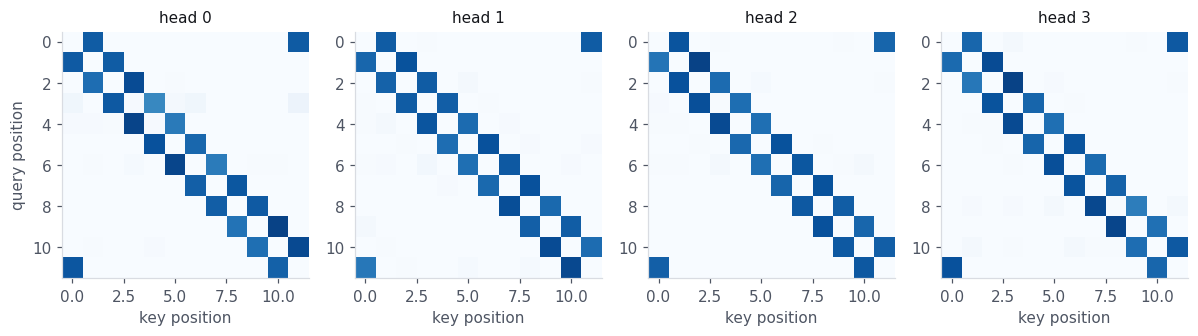

In [8]:
seed = 2
w = models[seed].attention_weights(x_val).mean(0)
fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
for h, ax in enumerate(axes):
    ax.imshow(w[h].detach(), cmap="Blues", vmin=0, vmax=0.6)
    ax.set_title(f"head {h}", fontsize=10, color=INK)
    ax.set_xlabel("key position"); ax.grid(False)
axes[0].set_ylabel("query position")
plt.tight_layout(); plt.show()

### What happens when a head is switched off?

`head_mask` multiplies a head's output by 0 before the heads are concatenated, so
the rest of the network is unchanged. If a head matters, accuracy should fall.

In [9]:
print(f"{'':10s}{'full model':>11s}" + "".join(f"{f'no head {h}':>11s}" for h in range(4)))
for seed, m in models.items():
    row = []
    for h in range(4):
        mask = torch.ones(4); mask[h] = 0
        row.append(accuracy(m, mask))
    print(f"seed {seed}   {accuracy(m):11.3f}" + "".join(f"{a:11.3f}" for a in row))

           full model  no head 0  no head 1  no head 2  no head 3
seed 0         1.000      0.979      0.886      0.802      0.493
seed 1         1.000      0.883      0.503      0.605      0.695
seed 2         1.000      0.794      0.617      0.587      0.832


Read these tables carefully, because they are not what the usual diagrams
promise.

- **Heads do not divide the job into the pieces we would name.** We might expect
  one head for the left neighbour and one for the right. Instead every head, in
  every seed, puts roughly half its weight on each side. The sum is a symmetric
  function of the two neighbours, so a head that averages both values carries the
  right information. (A task that treats the two sides differently, such as
  $x_{i-1} + 2\,x_{i+1}$, may be harder to learn and give messier heads; try it
  below.)
- **Heads are not equally important, and which one matters changes with the
  seed.** In seed 0 removing head 3 drops accuracy from 1.00 to 0.49, while
  removing head 0 costs only two points. In seed 1 the most important head is
  head 1, and in seed 2 it is head 2.
- **No single head is the whole solution.** Accuracy stays well above chance
  (0.167) after any one head is removed, because the other heads learned a
  similar pattern.

The honest summary: attention maps are worth looking at, but a story of the form
"head 3 does X" has to be checked by ablation, and it may not survive another
seed.

## Try it

1. Train with `n_heads = 2` instead of 4 (the same 1500 updates, three seeds).
   Is each head now more important? Compare the ablation table.
2. Replace the target with $(x_{i-1} + 2\,x_{i+1}) \bmod 6$ and train for 2500
   updates with 2 and 4 heads. Does accuracy still reach 1.0 on every seed? Do
   the heads separate the left from the right?
3. Remove the position embedding in `NeighbourModel.hidden`. What happens to the
   accuracy, and why? (Part 3 explains it.)
4. A colleague says "head 2 is the syntax head". What evidence would you ask for?

## What this notebook showed

- Multi-head attention is scaled dot-product attention applied to `n_heads`
  slices of the width at once, followed by a concatenation and one linear layer.
  The parameter count is the same for any number of heads.
- Our implementation matches `nn.MultiheadAttention` once the stacked query, key
  and value weights are copied across.
- On a two-lookup task, trained heads did not divide the lookups cleanly. Every
  head learned the same pattern, half its weight on each neighbour, and the cost of
  removing a head varied from two points to over fifty depending on the head and
  the seed.